In [11]:
import numpy as np 
import matplotlib.pyplot as plt
from hcipy import *
import os
import sys

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from adcFitter_onsky import AdcFitter

In [12]:
fieldcube = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/unsats/7725_m1offset.fits')

In [13]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle)

In [14]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle)

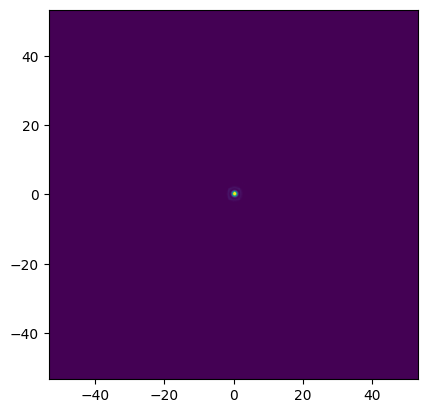

In [15]:
filtered_cube = []

for i, field in enumerate(fieldcube):
    filtered = ADC.crop_image(field,mask_diam=0) 
    filtered_cube.append(filtered)

imshow_field(filtered_cube[0])

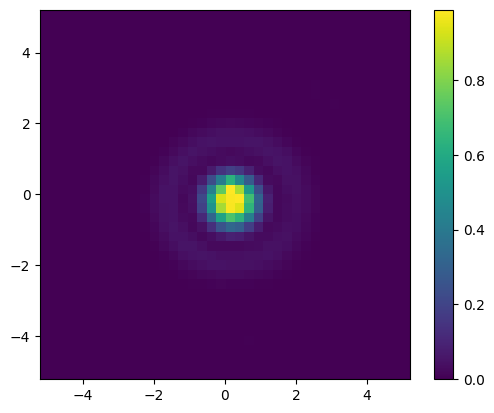

In [16]:
#measure the FWHM of every image, then average that to get the mean value for this ADC position
#most of this is pulled verbatim from /previous_onsky/gaussian_fwhm.ipynb

img = filtered_cube[0]

peak = np.argmax(img)
window_center = img.grid.points[peak]

pup = ADC.window_field(img,window_center,40,40) #this got its name because i first did it on pipup b
slice = pup.shaped[:,20]

plt.figure()
imshow_field(pup)
plt.colorbar()
plt.show()


4.598889730684769


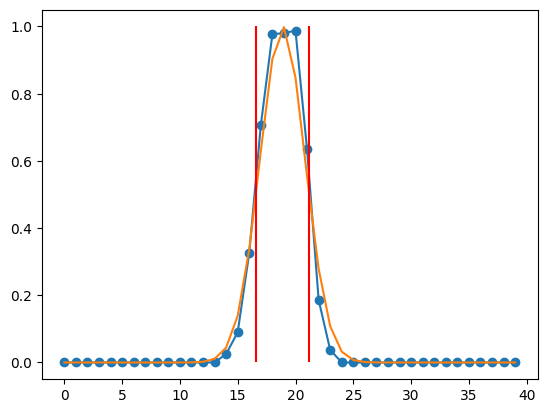

In [17]:
#start from the peak value and scan through the gradient outwards, find where the gradient switches direction. truncate the data there.
from scipy.optimize import curve_fit


def gauss(x,mu,sigma2):
    return np.exp(-(x-mu)**2 / (2 * sigma2) )

def isolate_gaussian(data):
    mid = np.argmax(data)
    first_derivative = np.gradient(data) 

    valley_indices = np.where((first_derivative[:-1] < 0) & (first_derivative[1:] > 0))[0] + 1

    left_valley = valley_indices[valley_indices < mid][-1] if any(valley_indices < mid) else None
    right_valley = valley_indices[valley_indices > mid][0] if any(valley_indices > mid) else None

    if left_valley is not None:
        data[0:left_valley] = 0
        #right_valley -= left_valley

    if right_valley is not None:
        data[right_valley:len(data)-1] = 0
        #print(right_valley)

    return data

def fwhm(data):
    isolated = isolate_gaussian(data)
    x = np.arange(40)
    popt = curve_fit(gauss,x,isolated,p0 = [20,4])

    mu = popt[0][0]
    sigma = popt[0][1]
    fwhm = 2 * np.sqrt(2 * np.log(2)) * np.sqrt(sigma)
    return fwhm, mu, sigma
    

width, mean, sd = fwhm(slice)
x = np.arange(40)
print(width)

s = isolate_gaussian(slice)

plt.figure()
plt.plot(s,'-o',label='Data')
plt.plot(x,gauss(x,mean,sd),'-',label='Fitted Gaussian')
plt.vlines(mean - width/2,0,1,'red')
plt.vlines(mean + width/2,0,1,'red')
plt.show()

In [18]:
widths = []

for img in filtered_cube:
    peak = np.argmax(img)
    window_center = img.grid.points[peak]

    pup = ADC.window_field(img,window_center,40,40)
    slice_column = np.array(np.unravel_index(np.argmax(pup),(40,40)))[0]
    slice = pup.shaped[:,slice_column]

    width, mean, sd = fwhm(slice)
    widths.append(width)

widths = np.array(widths)

In [19]:
print(np.mean(widths))
print(np.std(widths))


4.387194755021904
0.18372966199462967


In [20]:
#what if I don't filter the image?
